<a href="https://colab.research.google.com/github/DanisStepanov/image_processing/blob/main/%D0%A8%D0%B5%D0%B2%D0%B5%D0%BB%D0%B5%D0%B2_%D0%94%D0%BC%D0%B8%D1%82%D1%80%D0%B8%D0%B9_%D0%9B%D0%B5%D0%BE%D0%BD%D0%B8%D0%B4%D0%BE%D0%B2%D0%B8%D1%87%09_%D0%94%D0%9F%D0%9E_%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%965_%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%D1%81_%D1%80%D0%B0%D1%81%D1%82%D1%80%D0%BE%D0%B2%D1%8B%D0%BC%D0%B8_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D0%BC%D0%B8_%D0%B2_Rasterio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №5. Работа с растровыми данными в Rasterio**

---

**Данные для обработки:**

- Одноканальное изображение (ЦМР): https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
- Мультиспектральное изображение (Landsat): https://github.com/opengeos/datasets/releases/download/raster/cog.tif

In [1]:
!wget -q -nc https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
!wget -q -nc https://github.com/opengeos/datasets/releases/download/raster/cog.tif

In [43]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.windows import transform as window_transform
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

### **Задание 1. Чтение и исследование растровых данных**



1. Откройте одноканальное изображение ЦМР с использованием `rasterio`.


In [2]:
src_dem = rasterio.open('dem_90m.tif')
print(src_dem)

<open DatasetReader name='dem_90m.tif' mode='r'>


2. Извлеките и выведите метаданные растра, включая СК, разрешение, границы, количество каналов и типы данных.


In [4]:
print('СК:', src_dem.crs)
print('разрешение:', src_dem.res)
print('границы:', src_dem.bounds)
print('количество каналов:', src_dem.count)
print('типы данных:', src_dem.dtypes)

СК: EPSG:3857
разрешение: (90.0, 89.99579177642138)
границы: BoundingBox(left=-13442488.3428, bottom=4388214.6777, right=-13058278.3428, top=4668371.5775)
количество каналов: 1
типы данных: ('int16',)


3. Отобразите ширину и высоту растра, а также типы данных пикселей, чтобы понять размеры сетки и структуру данных.

In [7]:
print('Ширина столбцы', src_dem.width)
print('Высота строки', src_dem.height)
print('Тип данных пикселей', src_dem.dtypes[0])

dem_band = src_dem.read(1)
print('Размер массива', dem_band.shape)
print('Диапазон значений', dem_band.min(), '-', dem_band.max())

Ширина столбцы 4269
Высота строки 3113
Тип данных пикселей int16
Размер массива (3113, 4269)
Диапазон значений 15 - 4338


---



### **Задание 2. Визуализация и манипулирование растровыми каналами**



1. Визуализируйте одноканальное изображение ЦМР с использованием пользовательской цветовой карты (например, cmap='terrain').


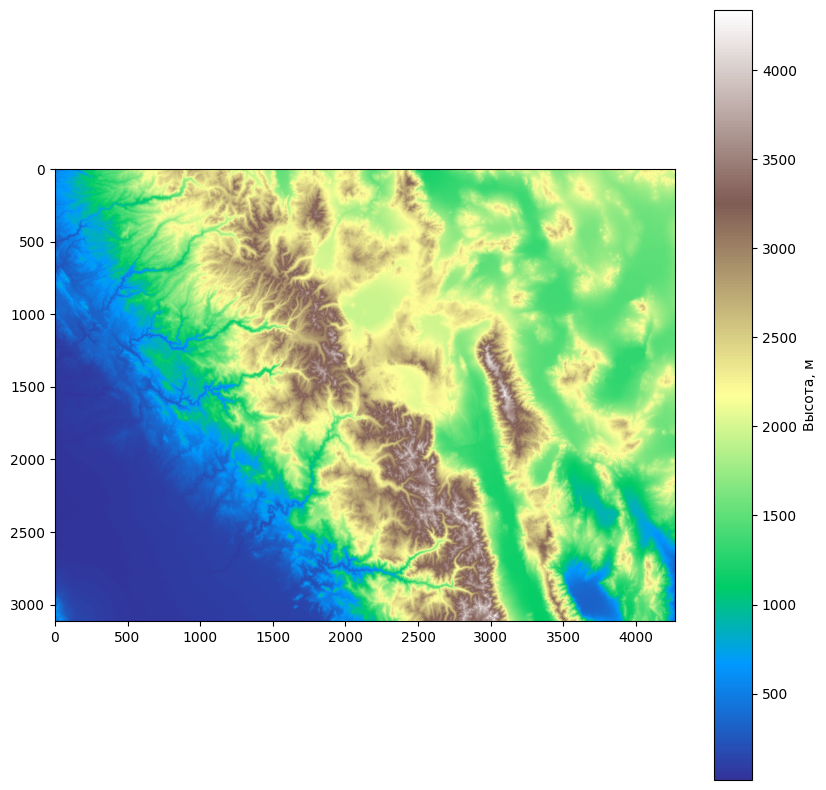

In [10]:
plt.figure(figsize=(10, 10))
plt.imshow(dem_band, cmap='terrain')
plt.colorbar(label='Высота, м')
plt.show()

2. Откройте мультиспектральное изображение и визуализируйте первый канал с использованием подходящей цветовой карты.


Каналов 4 | Тип float64 | CRS EPSG:4326


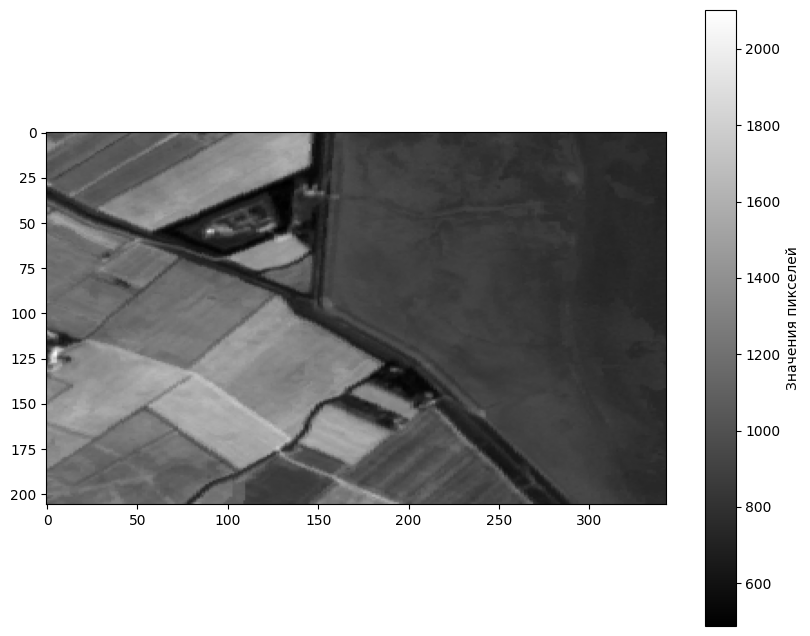

In [14]:
src_ms = rasterio.open('cog.tif')
print('Каналов', src_ms.count, '| Тип', src_ms.dtypes[0], '| CRS', src_ms.crs)
band1 = src_ms.read(1)
plt.figure(figsize=(10, 8))
plt.imshow(band1, cmap='gray')
plt.colorbar(label='Значения пикселей')
plt.show()

3. Объедините несколько каналов из мультиспектрального изображения (например, Красный, Зеленый и Синий) и совместите их в один массив для создания RGB-композитного изображения.

>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

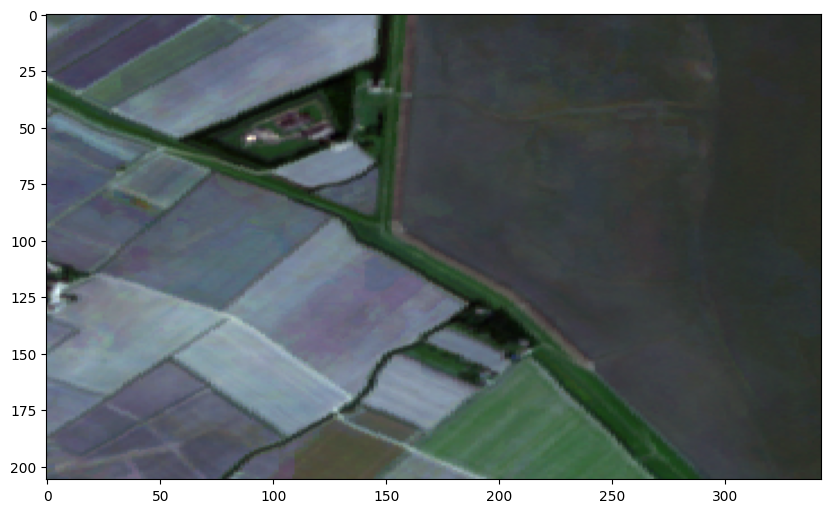

In [16]:
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm

red = normalize(src_ms.read(3))
green = normalize(src_ms.read(2))
blue = normalize(src_ms.read(1))

rgb = np.dstack((red, green, blue))
plt.figure(figsize=(10, 8))
plt.imshow(rgb)
plt.show()

---



### **Задание 3. Обрезка растра с использованием индексации массива**



1. Откройте мультиспектральное изображение и обрежьте его с использованием спискового среза (указав диапазоны строк и столбцов).


In [31]:
row_slice = slice(100, 500)
col_slice = slice(100, 500)
window = (row_slice, col_slice)
obrez = src_ms.read(window=window)
print(obrez.shape)

(4, 106, 243)


2. Визуализируйте обрезанную часть изображения с использованием matplotlib, чтобы убедиться в корректном результате.


>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

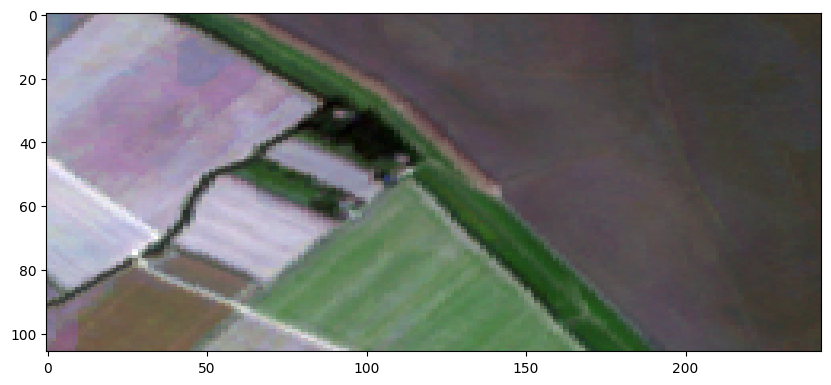

In [32]:
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm


obrez_rgb = np.dstack((normalize(obrez[2]),
                         normalize(obrez[1]),
                         normalize(obrez[0])))
plt.figure(figsize=(10, 10))
plt.imshow(obrez_rgb)
plt.show()

3. Сохраните обрезанное подмножество растра в новый файл с именем `clipped_multispectral.tif`.

In [35]:
obrez_profile = src_ms.profile.copy()
obrez_profile.update(
    height=obrez.shape[1],
    width=obrez.shape[2],
    transform=window_transform(rasterio.windows.Window(col_slice.start,
                                                       row_slice.start,
                                                       col_slice.stop - col_slice.start,
                                                       row_slice.stop - row_slice.start),
                                                        src_ms.transform)
)
with rasterio.open('final.tif', 'w', **obrez_profile) as dst_clip:
    dst_clip.write(obrez)

---



### **Задание 4. Вычисление NDWI (калькуляция каналов)**



1. Откройте мультиспектральное изображение и извлеките каналы Green (Зеленый) и Ближний инфракрасный (NIR).


In [37]:
green = src_ms.read(2).astype('float32')
nir = src_ms.read(4).astype('float32')

2. Вычислите Нормализованный разностный водный индекс ([NDWI](https://en.wikipedia.org/wiki/Normalized_difference_water_index)) по формуле:

    NDWI = (Green - NIR) / (Green + NIR)

In [39]:
ndwi = (green - nir) / (green + nir)
print('NDWI', ndwi.min(), '-', ndwi.max())

NDWI -0.6217617 - 0.47722894


3. Визуализируйте результат NDWI с использованием цветовой карты, подходящей для воды (например, cmap='Blues'), чтобы выделить водные объекты.


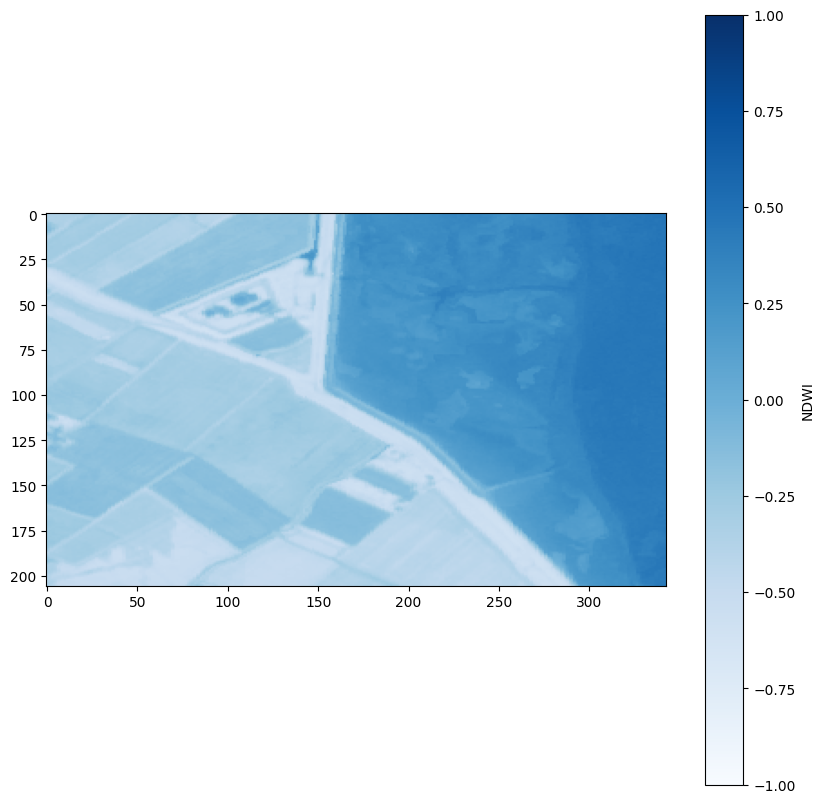

In [40]:
plt.figure(figsize=(10, 10))
plt.imshow(ndwi, cmap='Blues', vmin=-1, vmax=1)
plt.colorbar(label='NDWI')
plt.show()



4. Сохраните полученное изображение NDWI как новый растровый файл с именем ndwi.tif.

In [41]:
ndwi_profile = src_ms.profile.copy()
ndwi_profile.update(count=1, dtype='float32', nodata=np.nan)
with rasterio.open('ndwi_final.tif', 'w', **ndwi_profile) as dst_ndwi:
    dst_ndwi.write(ndwi, 1)

---



### **Задание 5. Перепроецирование растровых данных**



1. Перепроецируйте одноканальный растр ЦМР из его исходной СК в EPSG:4326 (WGS 84) с использованием функции `rasterio.warp.reproject`.


In [47]:
dst_crs = 'EPSG:4326'
with rasterio.open('dem_90m.tif') as src:
    transform, width, height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds)

    kwargs = src.meta.copy()
    kwargs.update({'crs': dst_crs, 'transform': transform,
                   'width': width, 'height': height})

    with rasterio.open('reprojected_dem.tif', 'w', **kwargs) as dst:
        for i in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs,
                resampling=Resampling.bilinear)
src_reproj = rasterio.open('reprojected_dem.tif')
print('исходная СК', 'EPSG', '///// новая СК', src_reproj.crs)
print('Было', src_dem.width, src_dem.height,
      '/////Стало', src_reproj.width, src_reproj.height)

исходная СК EPSG ///// новая СК EPSG:4326
Было 4269 3113 /////Стало 4575 2642


2. Сохраните перепроецированный растр в новый файл GeoTIFF с именем `reprojected_dem.tif`.


3. Визуализируйте как исходный, так и перепроецированный наборы данных ЦМР, чтобы сравнить, как перепроецирование влияет на пространственное покрытие и разрешение.

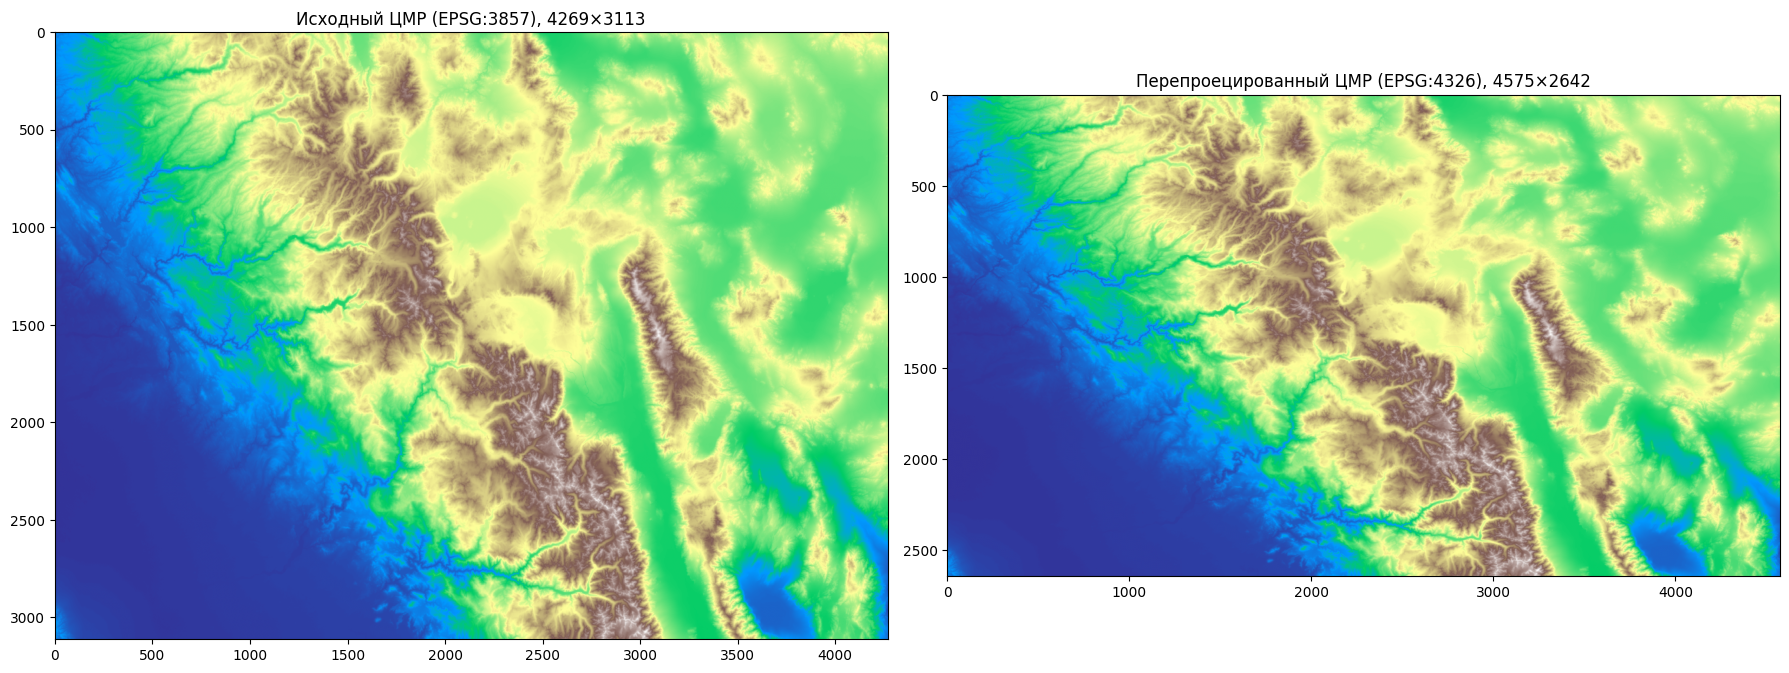

In [48]:
dem_reproj = src_reproj.read(1)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].imshow(dem_band, cmap='terrain')
axes[0].set_title(f'Исходный ЦМР ({src_dem.crs}), {src_dem.width}×{src_dem.height}')
axes[1].imshow(dem_reproj, cmap='terrain')
axes[1].set_title(f'Перепроецированный ЦМР ({src_reproj.crs}), {src_reproj.width}×{src_reproj.height}')
plt.tight_layout()
plt.show()

---